# Combined results across benchmarks (SBM / GRG / SuiteSparse)

Loads the three normalized-stress comparison tables and reports each method's
symmetric percent change (SPC) against `s_gd2`, side by side across all three
graph families. This does *not* pool instances across benchmarks for the
paired comparison -- `exp_idx` is only unique within a single family's CSV, so
every paired computation below is done per-benchmark first and only the
resulting SPC values are combined for the table/plots.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
from pathlib import Path

RESULTS_PATH = './results' if Path('./results').exists() else '../verification_experiments/results'
assert Path(RESULTS_PATH).exists()

BENCHMARKS = ['sbm', 'grg', 'suitesparse']
BENCH_LABELS = {'sbm': 'SBM', 'grg': 'GRG', 'suitesparse': 'SuiteSparse'}

# GRG results are split into toroidal vs euclidean variants for reporting
# (SBM/SuiteSparse have no such split) -- table columns and plot panels below
# are indexed by "group" rather than "benchmark": group == benchmark except
# for GRG, which becomes grg_toroidal / grg_euclidean.
GROUPS = ['sbm', 'grg_toroidal', 'grg_euclidean', 'suitesparse']
GROUP_LABELS = {
    'sbm': 'SBM',
    'grg_toroidal': 'GRG (toroidal)',
    'grg_euclidean': 'GRG (euclidean)',
    'suitesparse': 'SuiteSparse',
}
# Which dfs[...]/BENCHMARKS entry a group's rows actually live in -- needed
# by draw_instance() below, since dfs is still keyed by benchmark (grg's two
# graph types share one comparison CSV), not by group.
GROUP_BENCHMARK = {'sbm': 'sbm', 'grg_toroidal': 'grg', 'grg_euclidean': 'grg', 'suitesparse': 'suitesparse'}

METHODS = [
    's_gd2', 'wrap_python',
    'TorusMDS_spectral_init', 'TorusMDS_smart_1x_scale2', 'TorusMDS_random_1x_scale2',
]
METHODS_NO_BASE = [m for m in METHODS if m != 's_gd2']
COLORS = {
    's_gd2':                     '#4C72B0',
    'wrap_python':               '#55A868',
    'TorusMDS_spectral_init':    '#999999',
    'TorusMDS_smart_1x_scale2':  '#D65F66',
    'TorusMDS_random_1x_scale2': '#8172B2',
}

# Metrics common to all three families' comparison CSVs. Runtime (t_embed) is
# intentionally excluded here -- this notebook only compares layout quality.
ALL_METRICS = ['stress', 'sgs', 'np_score']
METRIC_LABELS = {'stress': 'Stress', 'sgs': 'SGS', 'np_score': 'NP'}
# stress is lower-is-better; SGS (Spearman rank correlation) and NP (neighbourhood
# precision) are both higher-is-better -- used to orient "win rate" (cell below) and
# the LaTeX table captions consistently per metric.
METRIC_HIGHER_IS_BETTER = {'stress': False, 'sgs': True, 'np_score': True}

dfs = {}
for b in BENCHMARKS:
    d = pd.read_csv(f'{RESULTS_PATH}/{b}_normalized_comparison.csv')
    d['benchmark'] = b
    dfs[b] = d

print('--- graph counts per method, per benchmark ---')
for b in BENCHMARKS:
    print(f'\n{BENCH_LABELS[b]}:')
    print(dfs[b].groupby('method')['exp_idx'].nunique().reindex(METHODS))

--- graph counts per method, per benchmark ---

SBM:
method
s_gd2                        770
wrap_python                  638
TorusMDS_spectral_init       770
TorusMDS_smart_1x_scale2     770
TorusMDS_random_1x_scale2    770
Name: exp_idx, dtype: int64

GRG:
method
s_gd2                        980
wrap_python                  729
TorusMDS_spectral_init       980
TorusMDS_smart_1x_scale2     980
TorusMDS_random_1x_scale2    980
Name: exp_idx, dtype: int64

SuiteSparse:
method
s_gd2                        1040
wrap_python                   818
TorusMDS_spectral_init       1040
TorusMDS_smart_1x_scale2     1040
TorusMDS_random_1x_scale2    1040
Name: exp_idx, dtype: int64


## Paired comparison helpers

Same SPC definition used in the per-family notebooks: for a matched pair of
instances (same `exp_idx`, same benchmark), `SPC = 100 * (A - B) / max(|A|, |B|)`.
Unlike a plain percent change, this is bounded to `[-100, 100]` regardless of
how small the baseline value is, which matters for metrics like stress that
can vary by orders of magnitude across graph sizes. `MIN_N_FOR_DIST` matches
the per-family notebooks: a method needs at least 5 matched instances against
`s_gd2` in a given benchmark for its distribution to be shown at all
(`wrap_python` is capped at `n <= wrap-python-max-n`, so it can fall short on
the largest-graph tiers).

In [2]:
MIN_N_FOR_DIST = 5
N_BOOT = 2000


def paired_spc_long(df, methods, baseline, id_col, metrics, extra_cols=None):
    """Per-instance symmetric percent change vs `baseline`, matched on `id_col`."""
    extra_cols = extra_cols or []
    base = df[df['method'] == baseline].set_index(id_col)
    frames = []
    for m in methods:
        if m == baseline:
            continue
        other = df[df['method'] == m].set_index(id_col)
        common = base.index.intersection(other.index)
        if len(common) == 0:
            continue
        for metric in metrics:
            a = other.loc[common, metric]
            b = base.loc[common, metric]
            denom = np.maximum(a.abs(), b.abs())
            spc = 100 * (a - b) / denom
            frame = pd.DataFrame({
                'method': m, 'metric': metric, id_col: common, 'spc': spc.values,
            })
            for col in extra_cols:
                frame[col] = base.loc[common, col].values
            frames.append(frame)
    if not frames:
        return pd.DataFrame(columns=['method', 'metric', id_col, 'spc'] + extra_cols)
    return pd.concat(frames, ignore_index=True)


def bootstrap_median_ci(vals, n_boot=N_BOOT, ci=95, seed=0):
    rng = np.random.default_rng(seed)
    vals = np.asarray(vals, dtype=float)
    boots = rng.choice(vals, size=(n_boot, len(vals)), replace=True)
    boot_medians = np.median(boots, axis=1)
    lo, hi = np.percentile(boot_medians, [(100 - ci) / 2, 100 - (100 - ci) / 2])
    return np.median(vals), lo, hi


spc_frames = []
for b in BENCHMARKS:
    d = dfs[b]
    present = [m for m in METHODS if m in d['method'].unique()]
    # GRG's comparison CSV has a 'graph_type' column (toroidal/euclidean);
    # SBM/SuiteSparse don't -- carry it through only when it exists so the
    # resulting group tag can split GRG below.
    extra_cols = ['graph_type'] if 'graph_type' in d.columns else []
    long = paired_spc_long(d, present, 's_gd2', 'exp_idx', ALL_METRICS, extra_cols=extra_cols)
    long['benchmark'] = b
    long['group'] = (b + '_' + long['graph_type']) if 'graph_type' in long.columns else b
    spc_frames.append(long)
spc_all = pd.concat(spc_frames, ignore_index=True)

n_matched = spc_all.groupby(['group', 'metric', 'method'])['spc'].count().unstack(['group', 'metric'])
n_matched.reindex(METHODS_NO_BASE)

group                     grg_euclidean             grg_toroidal              \
metric                         np_score  sgs stress     np_score  sgs stress   
method                                                                         
wrap_python                         362  362    362          367  367    367   
TorusMDS_spectral_init              489  489    489          491  491    491   
TorusMDS_smart_1x_scale2            489  489    489          491  491    491   
TorusMDS_random_1x_scale2           489  489    489          491  491    491   

group                          sbm             suitesparse               
metric                    np_score  sgs stress    np_score   sgs stress  
method                                                                   
wrap_python                    638  638    638         818   817    818  
TorusMDS_spectral_init         770  770    770        1040  1039   1040  
TorusMDS_smart_1x_scale2       770  770    770        1039  1039   1040  
TorusMDS_random_1x_scale2      770  770    770        1040  1039   1040

## LaTeX summary tables: median SPC vs `s_gd2` (stress, SGS, NP)

One table per metric, methods as rows and benchmarks as columns. Each cell is
the median paired SPC with a 95% bootstrap CI (`--` where a method has fewer
than `MIN_N_FOR_DIST` matched instances against `s_gd2` in that benchmark).
Stress is lower-is-better, so negative stress SPC means better stress than
`s_gd2`; SGS and NP are both higher-is-better, so positive SPC means better
SGS/NP than `s_gd2`.

In [3]:
def spc_cell(vals):
    vals = np.asarray(vals, dtype=float)
    vals = vals[~np.isnan(vals)]
    if len(vals) < MIN_N_FOR_DIST:
        return '--'
    # med, lo, hi = bootstrap_median_ci(vals)
    med = vals.mean()
    return f'{med:.1f}'


def build_spc_table(metric):
    rows = []
    for m in METHODS_NO_BASE:
        row = {'Method': m}
        for g in GROUPS:
            sub = spc_all[(spc_all['group'] == g) & (spc_all['metric'] == metric) & (spc_all['method'] == m)]
            row[GROUP_LABELS[g]] = spc_cell(sub['spc'].values)
        rows.append(row)
    return pd.DataFrame(rows).set_index('Method')


stress_table_df = build_spc_table('stress')
sgs_table_df = build_spc_table('sgs')
np_table_df = build_spc_table('np_score')

stress_table_df

,SBM,GRG (toroidal),GRG (euclidean),SuiteSparse
Method,,,,
wrap_python,2.4,-16.5,57.8,28.4
TorusMDS_spectral_init,-11.1,-35.1,73.9,36.9
TorusMDS_smart_1x_scale2,-14.4,-46.3,53.1,7.3
TorusMDS_random_1x_scale2,-14.1,-38.8,44.1,4.8


In [4]:
sgs_table_df

,SBM,GRG (toroidal),GRG (euclidean),SuiteSparse
Method,,,,
wrap_python,-37.5,-22.6,-6.5,-28.0
TorusMDS_spectral_init,-6.6,22.3,-20.8,-31.5
TorusMDS_smart_1x_scale2,-24.5,25.0,-21.0,-9.9
TorusMDS_random_1x_scale2,-27.4,6.9,-20.8,-10.2


In [5]:
np_table_df

,SBM,GRG (toroidal),GRG (euclidean),SuiteSparse
Method,,,,
wrap_python,-1.2,18.5,-0.6,-2.6
TorusMDS_spectral_init,-0.4,29.5,-31.6,-7.4
TorusMDS_smart_1x_scale2,-0.0,33.9,-25.1,-0.8
TorusMDS_random_1x_scale2,-0.1,22.2,-23.4,-0.4


In [6]:
def to_latex_table(table_df, metric_label, caption_extra, label, out_path):
    latex_str = table_df.to_latex(
        column_format='l' + 'c' * len(table_df.columns),
        caption=(
            f'Median symmetric percent change (SPC) vs \\texttt{{s_gd2}} for {metric_label}, '
            f'with 95\\% bootstrap CI, across SBM, GRG (split into toroidal/euclidean), and '
            f'SuiteSparse. {caption_extra}'
        ),
        label=label,
    )
    latex_str = latex_str.replace("_", "\\_").replace("table", "table*")
    print(latex_str)
    with open(out_path, 'w') as f:
        f.write(latex_str)
    print(f'Saved to {out_path}')


to_latex_table(
    stress_table_df, 'stress',
    'Negative values indicate lower (better) stress than \\texttt{s\\_gd2}.',
    'tab:spc_summary_stress',
    f'{RESULTS_PATH}/spc_summary_table_stress.tex',
)
print()
to_latex_table(
    sgs_table_df, 'SGS',
    'SGS is higher-is-better, so positive values indicate higher (better) SGS than \\texttt{s\\_gd2}.',
    'tab:spc_summary_sgs',
    f'{RESULTS_PATH}/spc_summary_table_sgs.tex',
)
print()
to_latex_table(
    np_table_df, 'NP',
    'NP is higher-is-better, so positive values indicate higher (better) NP than \\texttt{s\\_gd2}.',
    'tab:spc_summary_np',
    f'{RESULTS_PATH}/spc_summary_table_np.tex',
)

\begin{table*}
\caption{Median symmetric percent change (SPC) vs \texttt{s\_gd2} for stress, with 95\% bootstrap CI, across SBM, GRG (split into toroidal/euclidean), and SuiteSparse. Negative values indicate lower (better) stress than \texttt{s\\_gd2}.}
\label{tab:spc\_summary\_stress}
\begin{tabular}{lcccc}
\toprule
 & SBM & GRG (toroidal) & GRG (euclidean) & SuiteSparse \\
Method &  &  &  &  \\
\midrule
wrap\_python & 2.4 & -16.5 & 57.8 & 28.4 \\
TorusMDS\_spectral\_init & -11.1 & -35.1 & 73.9 & 36.9 \\
TorusMDS\_smart\_1x\_scale2 & -14.4 & -46.3 & 53.1 & 7.3 \\
TorusMDS\_random\_1x\_scale2 & -14.1 & -38.8 & 44.1 & 4.8 \\
\bottomrule
\end{tabular}
\end{table*}

Saved to ../verification_experiments/results/spc_summary_table_stress.tex

\begin{table*}
\caption{Median symmetric percent change (SPC) vs \texttt{s\_gd2} for SGS, with 95\% bootstrap CI, across SBM, GRG (split into toroidal/euclidean), and SuiteSparse. SGS is higher-is-better, so positive values indicate higher (better) SGS 

## Strip plots: per-instance SPC distributions

Each dot is one matched graph instance; the black tick marks the median.
Rows are metrics (stress, SGS, NP), columns are benchmark/graph-type groups
(GRG is split into toroidal vs euclidean). Methods with fewer than
`MIN_N_FOR_DIST` matched instances in a given group are omitted from that
panel.

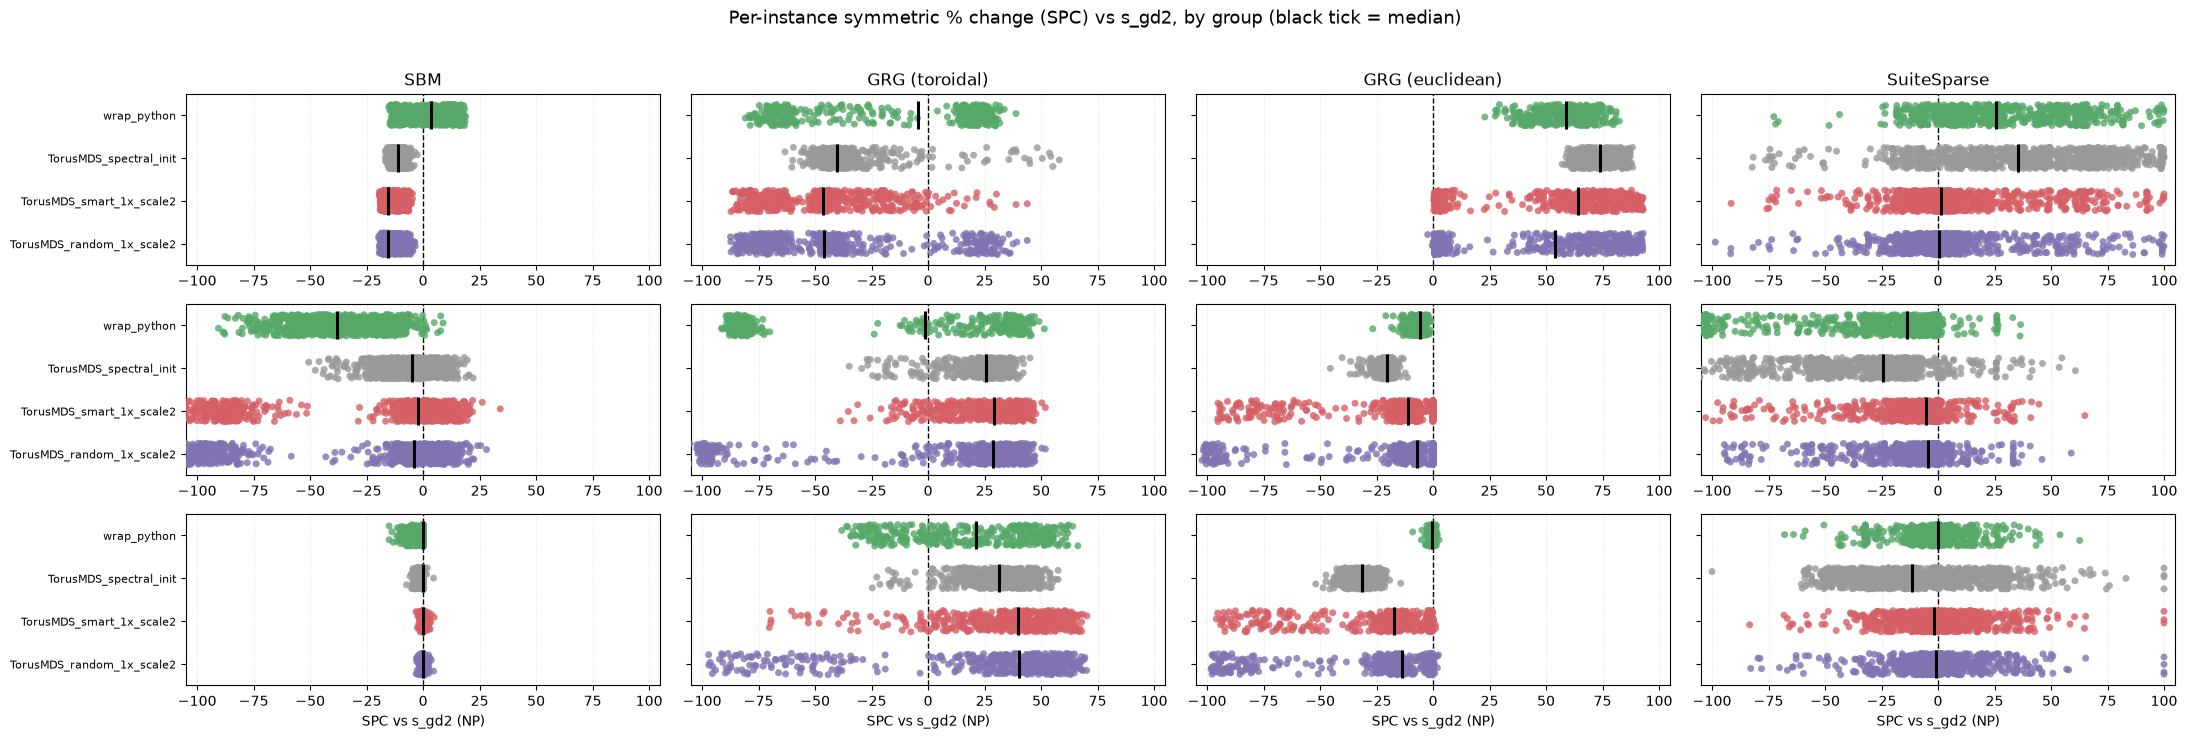

In [7]:
fig, axes = plt.subplots(
    len(ALL_METRICS), len(GROUPS),
    figsize=(5.5 * len(GROUPS), 0.6 * len(METHODS_NO_BASE) + 1.6 * len(ALL_METRICS)),
    squeeze=False,
)

for ri, metric in enumerate(ALL_METRICS):
    for gi, g in enumerate(GROUPS):
        ax = axes[ri][gi]
        sub = spc_all[(spc_all['group'] == g) & (spc_all['metric'] == metric)]
        present_methods = [m for m in METHODS_NO_BASE if sub[sub['method'] == m]['spc'].count() >= MIN_N_FOR_DIST]
        sub = sub[sub['method'].isin(present_methods)]

        if len(sub) > 0:
            sns.stripplot(
                data=sub, x='spc', y='method', order=present_methods, hue='method',
                hue_order=present_methods, palette=COLORS, size=5, alpha=0.8, jitter=0.25,
                ax=ax, legend=False,
            )
            for yi, m in enumerate(present_methods):
                vals = sub[sub['method'] == m]['spc'].dropna().values
                ax.scatter(np.median(vals), yi, marker='|', s=400, linewidths=2.2, color='black', zorder=5)

        ax.axvline(0, color='black', linestyle='--', linewidth=1)
        ax.set_xlim(-105, 105)
        ax.set_yticks(range(len(METHODS_NO_BASE)))
        ax.set_yticklabels(METHODS_NO_BASE if gi == 0 else [''] * len(METHODS_NO_BASE), fontsize=8)
        ax.set_ylim(len(METHODS_NO_BASE) - 0.5, -0.5)
        ax.set_xlabel(f'SPC vs s_gd2 ({METRIC_LABELS[metric]})' if ri == len(ALL_METRICS) - 1 else '')
        ax.set_ylabel('')
        if ri == 0:
            ax.set_title(GROUP_LABELS[g], fontsize=12)
        ax.grid(axis='x', linestyle='--', alpha=0.3)

fig.suptitle('Per-instance symmetric % change (SPC) vs s_gd2, by group (black tick = median)', fontsize=13, y=1.02)
fig.tight_layout()
plt.savefig(f'{RESULTS_PATH}/combined_spc_strip.png', dpi=150, bbox_inches='tight')
plt.show()

## CI plots: median SPC with 95% bootstrap CI

Same grid layout (rows = metrics, columns = benchmark/graph-type groups) as
the strip plots above, but showing just the median SPC per method with a 95%
bootstrap CI -- the point estimates behind the summary table.

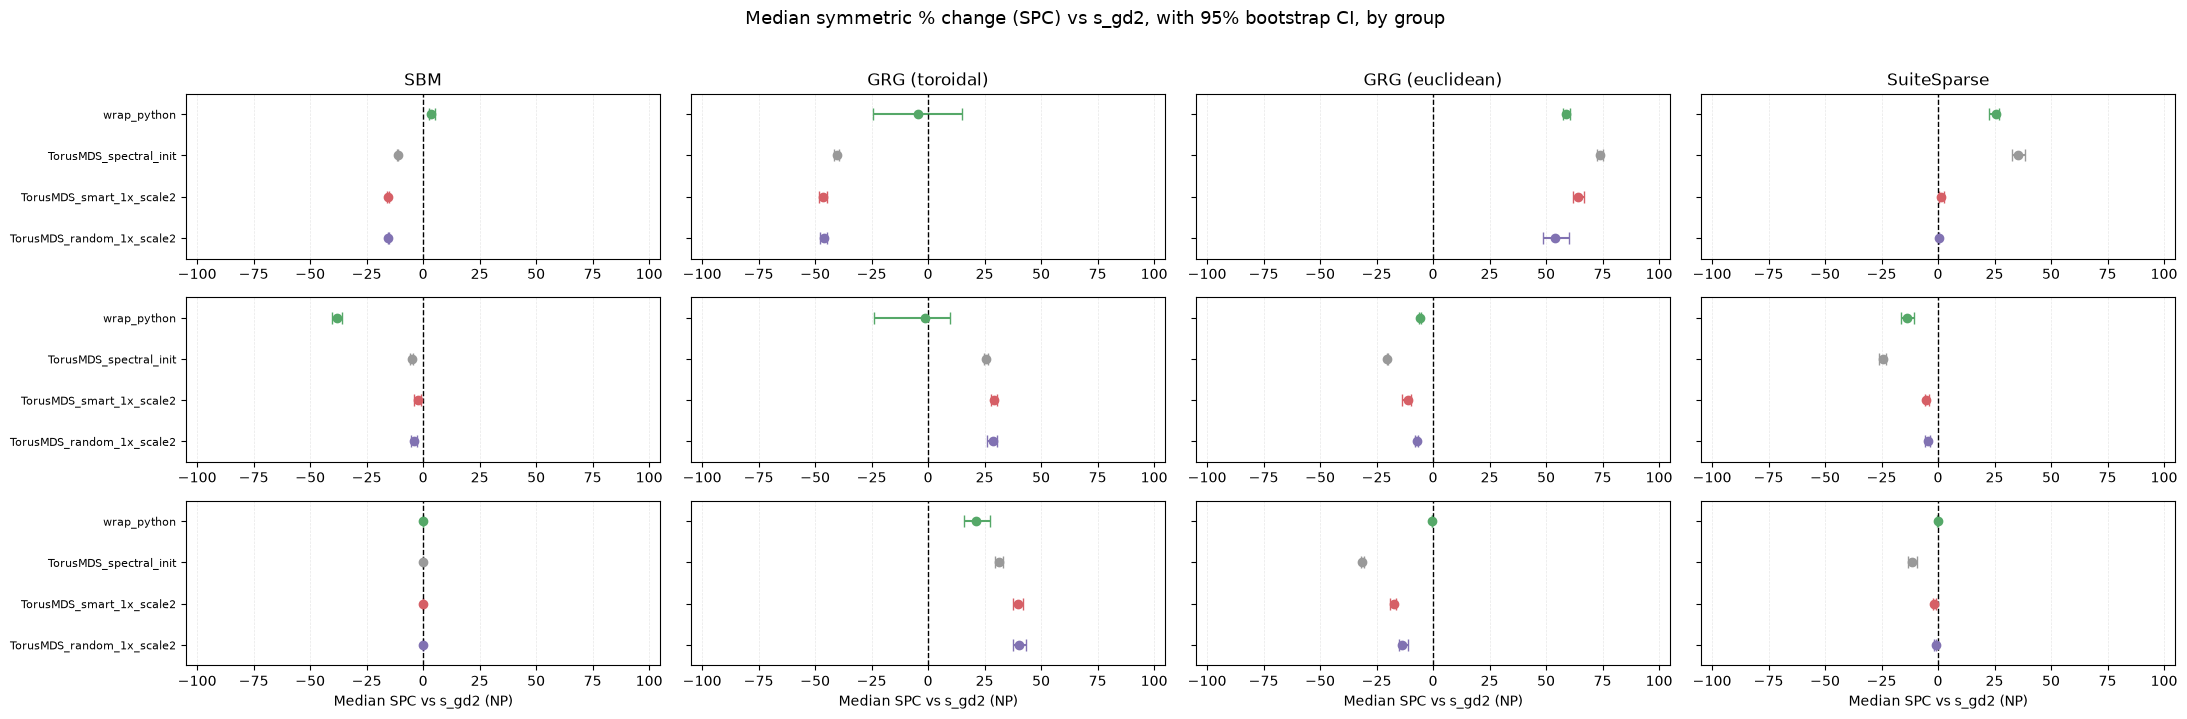

In [8]:
fig, axes = plt.subplots(
    len(ALL_METRICS), len(GROUPS),
    figsize=(5.5 * len(GROUPS), 0.55 * len(METHODS_NO_BASE) + 1.6 * len(ALL_METRICS)),
    squeeze=False,
)

for ri, metric in enumerate(ALL_METRICS):
    for gi, g in enumerate(GROUPS):
        ax = axes[ri][gi]
        sub = spc_all[(spc_all['group'] == g) & (spc_all['metric'] == metric)]

        for yi, m in enumerate(METHODS_NO_BASE):
            vals = sub[sub['method'] == m]['spc'].dropna().values
            if len(vals) < MIN_N_FOR_DIST:
                continue
            med, lo, hi = bootstrap_median_ci(vals)
            ax.errorbar(med, yi, xerr=[[med - lo], [hi - med]], fmt='o', color=COLORS[m], capsize=4, markersize=6)

        ax.axvline(0, color='black', linestyle='--', linewidth=1)
        ax.set_xlim(-105, 105)
        ax.set_yticks(range(len(METHODS_NO_BASE)))
        ax.set_yticklabels(METHODS_NO_BASE if gi == 0 else [''] * len(METHODS_NO_BASE), fontsize=8)
        ax.set_ylim(len(METHODS_NO_BASE) - 0.5, -0.5)
        ax.set_xlabel(f'Median SPC vs s_gd2 ({METRIC_LABELS[metric]})' if ri == len(ALL_METRICS) - 1 else '')
        ax.set_ylabel('')
        if ri == 0:
            ax.set_title(GROUP_LABELS[g], fontsize=12)
        ax.grid(axis='x', linestyle='--', alpha=0.3)

fig.suptitle('Median symmetric % change (SPC) vs s_gd2, with 95% bootstrap CI, by group', fontsize=13, y=1.02)
fig.tight_layout()
plt.savefig(f'{RESULTS_PATH}/combined_spc_ci.png', dpi=150, bbox_inches='tight')
plt.show()

## Histograms: SPC distribution shape

Strip plots overplot heavily at these sample sizes (up to ~1000 points per
panel) -- histograms show the actual distribution shape (skew, multimodality,
how much mass piles up at the +-100 boundary) that the strip/CI views collapse
away.

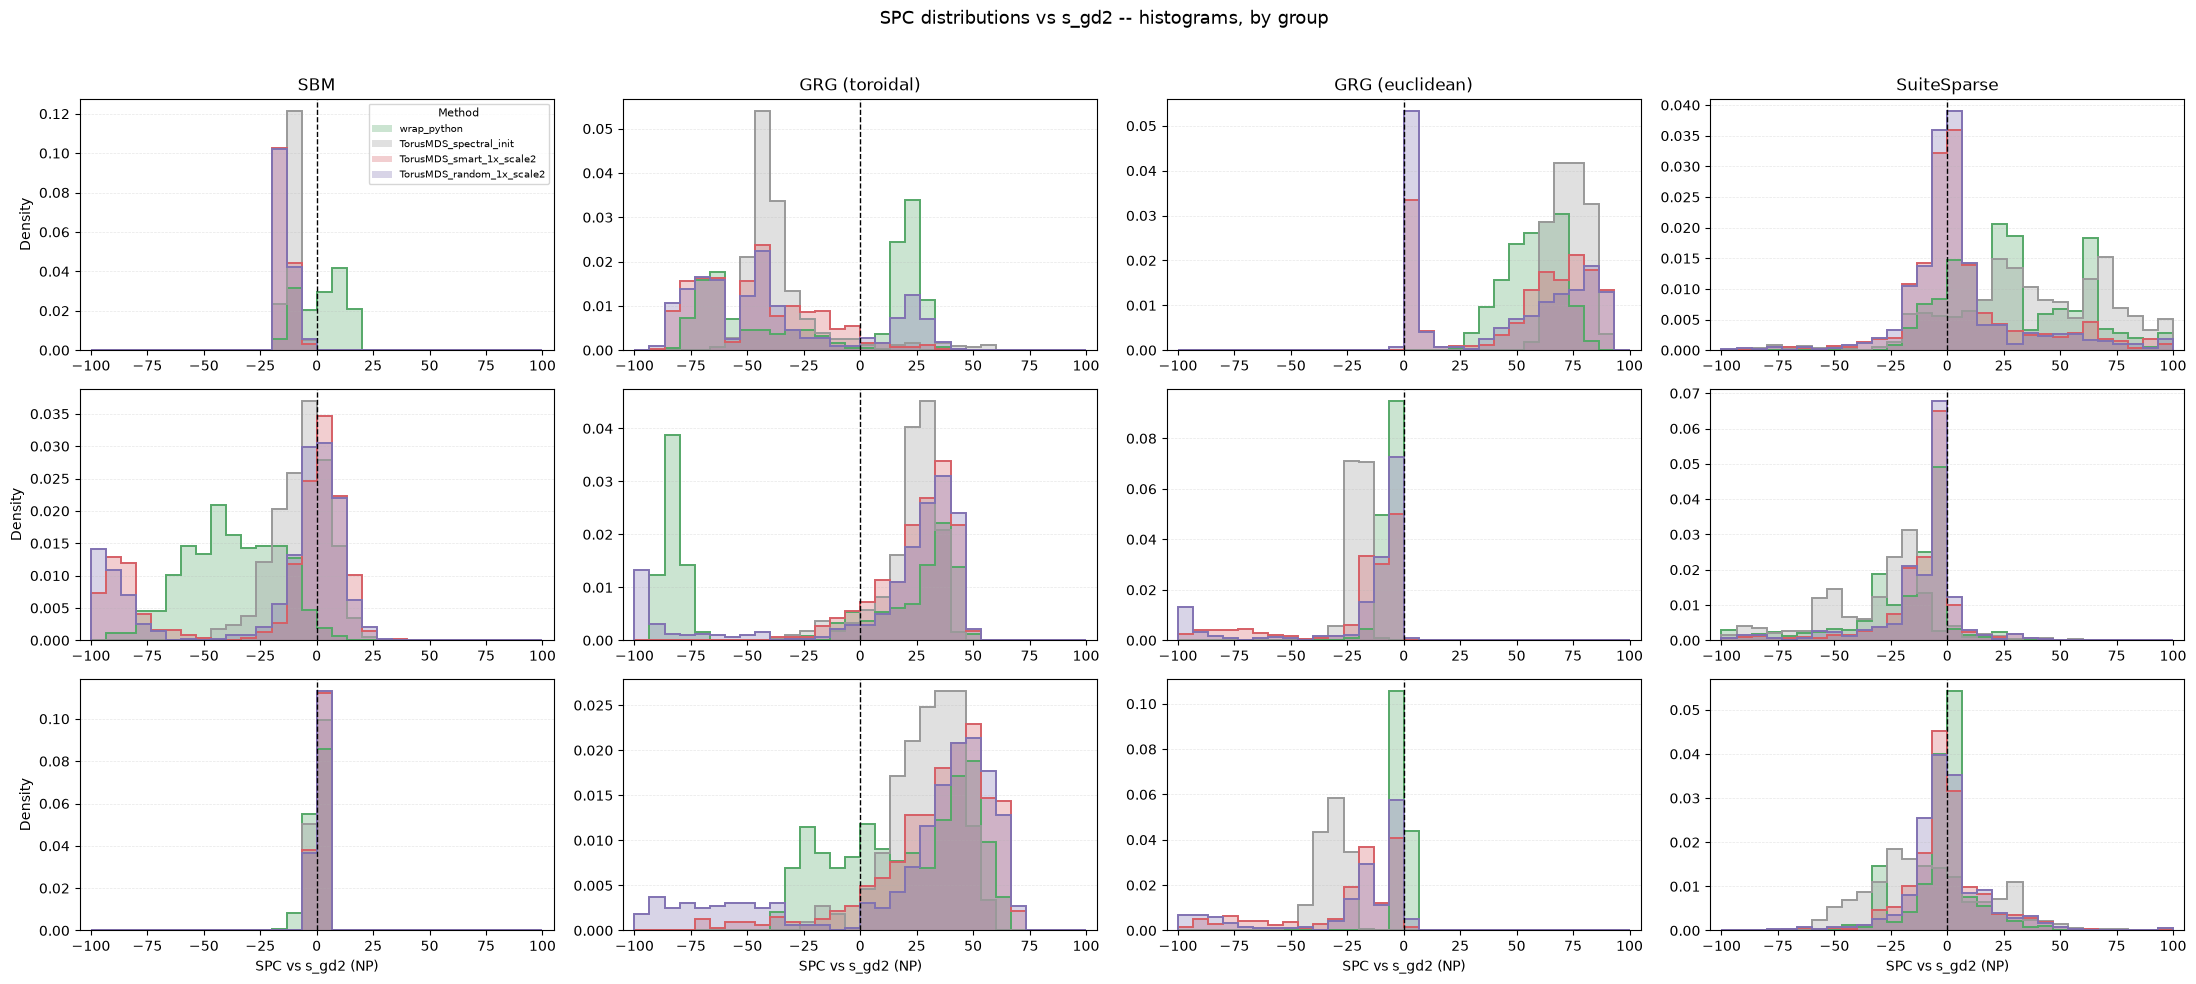

In [9]:
fig, axes = plt.subplots(
    len(ALL_METRICS), len(GROUPS),
    figsize=(5.5 * len(GROUPS), 3.2 * len(ALL_METRICS)),
    squeeze=False,
)

for ri, metric in enumerate(ALL_METRICS):
    for gi, g in enumerate(GROUPS):
        ax = axes[ri][gi]
        sub = spc_all[(spc_all['group'] == g) & (spc_all['metric'] == metric)]
        present_methods = [m for m in METHODS_NO_BASE if sub[sub['method'] == m]['spc'].count() >= MIN_N_FOR_DIST]

        for m in present_methods:
            vals = sub[sub['method'] == m]['spc'].dropna().values
            ax.hist(vals, bins=30, range=(-100, 100), density=True, histtype='stepfilled',
                    alpha=0.3, color=COLORS[m], label=m)
            ax.hist(vals, bins=30, range=(-100, 100), density=True, histtype='step',
                    linewidth=1.4, color=COLORS[m])

        ax.axvline(0, color='black', linestyle='--', linewidth=1)
        ax.set_xlim(-105, 105)
        ax.set_xlabel(f'SPC vs s_gd2 ({METRIC_LABELS[metric]})' if ri == len(ALL_METRICS) - 1 else '')
        ax.set_ylabel('Density' if gi == 0 else '')
        if ri == 0:
            ax.set_title(GROUP_LABELS[g], fontsize=12)
        ax.grid(axis='y', linestyle='--', alpha=0.3)

axes[0][0].legend(fontsize=7, title='Method', title_fontsize=8)
fig.suptitle('SPC distributions vs s_gd2 -- histograms, by group', fontsize=13, y=1.02)
fig.tight_layout()
plt.savefig(f'{RESULTS_PATH}/combined_spc_hist.png', dpi=150, bbox_inches='tight')
plt.show()

## KDE plots: SPC distribution shape

Same data as the histograms above, smoothed. Caveat: some distributions can
pile up hard against the +-100 boundary -- a KDE assumes unbounded support,
so near that edge it can smear a sharp spike into a softer hump that then
gets clipped at the boundary, rather than showing the true spike the
histogram above does. Read the two together, not the KDE alone.

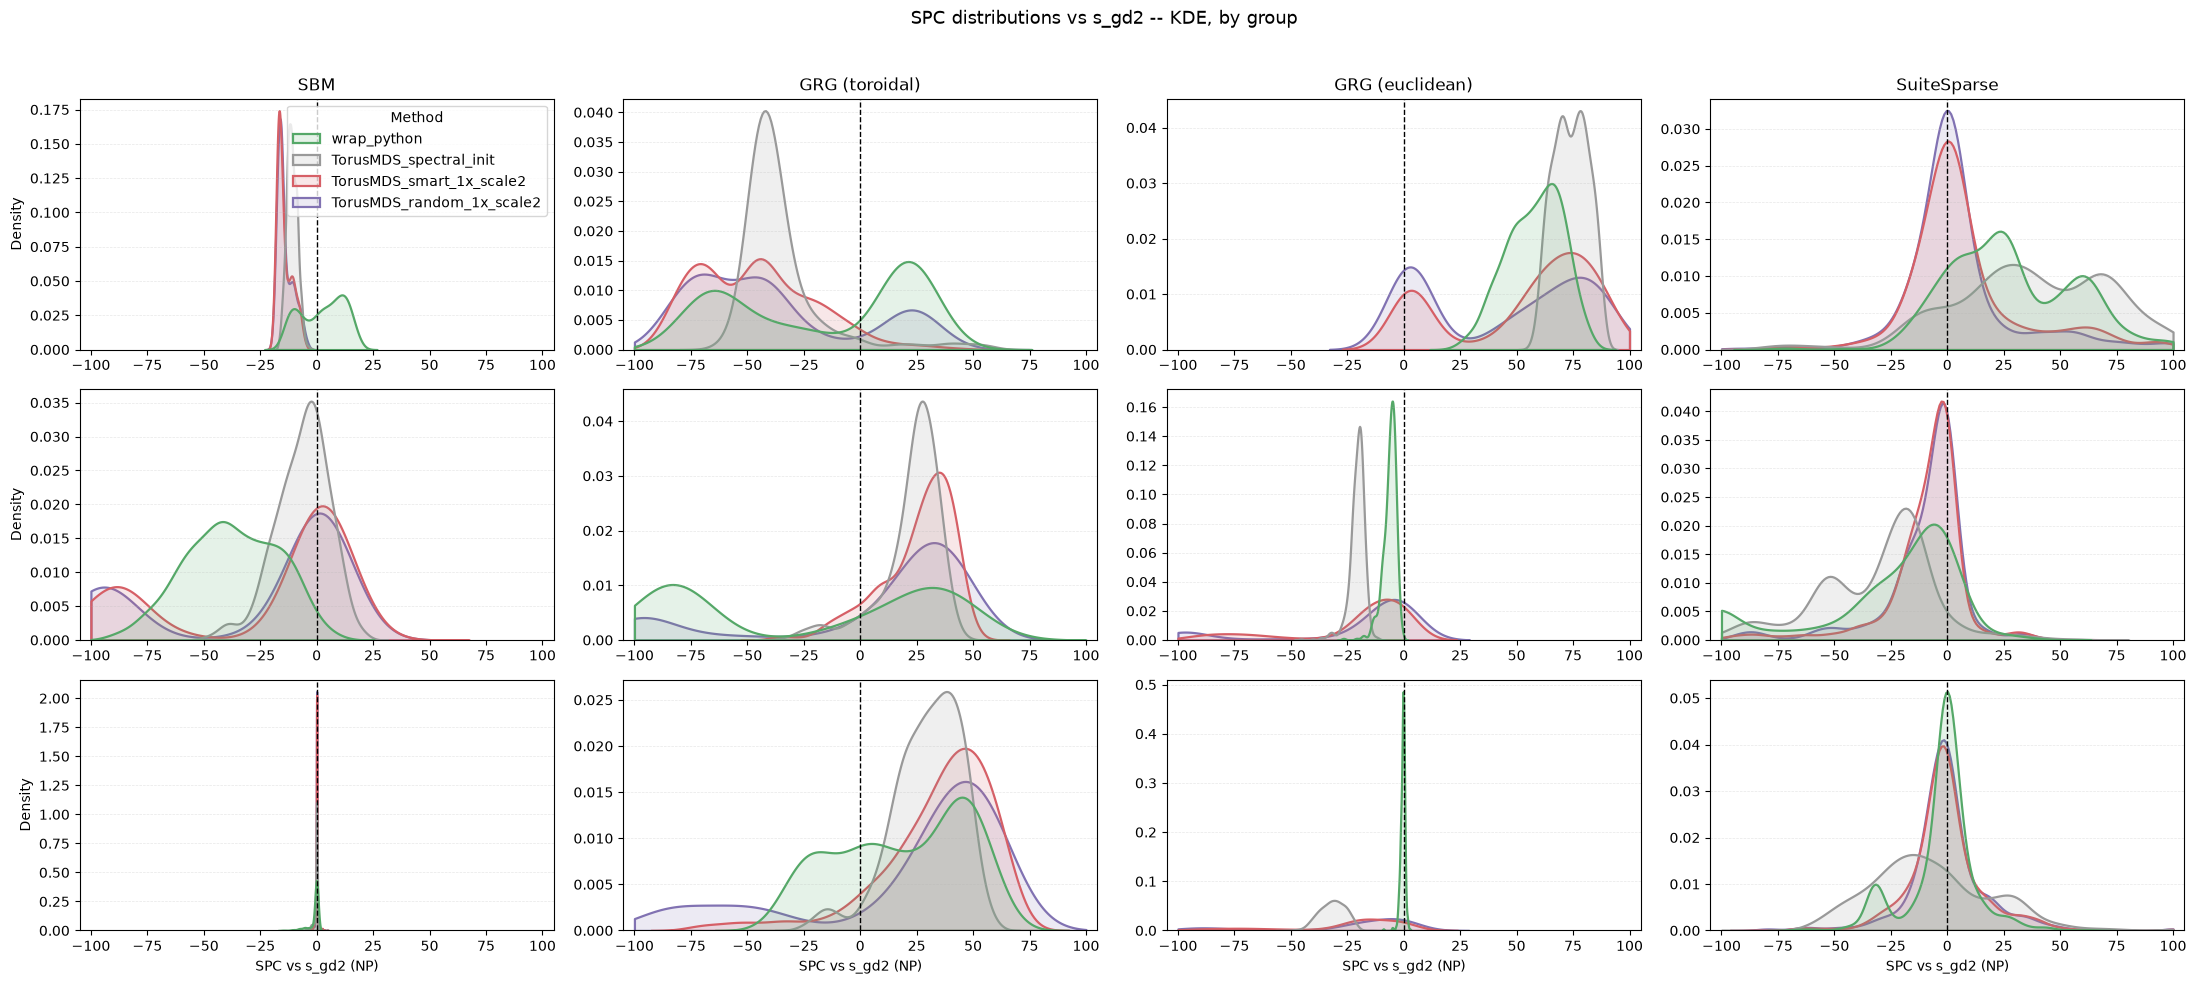

In [10]:
fig, axes = plt.subplots(
    len(ALL_METRICS), len(GROUPS),
    figsize=(5.5 * len(GROUPS), 3.2 * len(ALL_METRICS)),
    squeeze=False,
)

for ri, metric in enumerate(ALL_METRICS):
    for gi, g in enumerate(GROUPS):
        ax = axes[ri][gi]
        sub = spc_all[(spc_all['group'] == g) & (spc_all['metric'] == metric)]
        present_methods = [m for m in METHODS_NO_BASE if sub[sub['method'] == m]['spc'].count() >= MIN_N_FOR_DIST]
        sub = sub[sub['method'].isin(present_methods)]

        if len(sub) > 0:
            sns.kdeplot(
                data=sub, x='spc', hue='method', hue_order=present_methods, palette=COLORS,
                clip=(-100, 100), fill=True, alpha=0.15, linewidth=1.6, common_norm=False,
                ax=ax, legend=(ri == 0 and gi == 0),
            )

        ax.axvline(0, color='black', linestyle='--', linewidth=1)
        ax.set_xlim(-105, 105)
        ax.set_xlabel(f'SPC vs s_gd2 ({METRIC_LABELS[metric]})' if ri == len(ALL_METRICS) - 1 else '')
        ax.set_ylabel('Density' if gi == 0 else '')
        if ri == 0:
            ax.set_title(GROUP_LABELS[g], fontsize=12)
        ax.grid(axis='y', linestyle='--', alpha=0.3)

if axes[0][0].get_legend() is not None:
    axes[0][0].get_legend().set_title('Method')

fig.suptitle('SPC distributions vs s_gd2 -- KDE, by group', fontsize=13, y=1.02)
fig.tight_layout()
plt.savefig(f'{RESULTS_PATH}/combined_spc_kde.png', dpi=150, bbox_inches='tight')
plt.show()

## Raincloud comparisons: comparison CSVs or layout metrics

Set `RAINCLOUD_SOURCE` below to `"comparison"` (default) or `"layout_metrics"`.
The cell loads its own data and can run independently. `RAINCLOUD_TIERS` optionally
restricts layout tiers. Shard CSVs are merged in memory, with shard-qualified graph
identities. Parallelogram is included in both sources wherever available; absent
methods are reported rather than filled from a different evaluation pipeline.

Layout metrics add silhouette, crossings, normalized cluster distance and incidence.
Each method is paired with SGD2 on available valid values, so counts differ.
Cluster panels require labels; crossings are limited to graphs actually evaluated.
Partial rows remain usable for metrics that succeeded. These sources use different
sampling conventions; their values should not be mixed.

Black ticks mark means, and labels show paired counts. Negative SPC favors lower-is-better
metrics (stress, crossings, incidence); positive SPC favors SGS, NP and cluster scores.
SPC is `100*(method-baseline)/max(abs(method),abs(baseline))`; both zero gives zero.
Signed metrics can reach +/-200%, and plot limits expand accordingly.
Images go into source-specific `results/raincloud_<source>/` directories.

Set `RAINCLOUD_SHARED_INSTANCES = True` (default) to require identical valid graph
instances for all compared methods, separately for each group and metric.
`False` restores independent method-versus-SGD2 matching. By default, methods
absent from an entire group are omitted; set `RAINCLOUD_METHODS` explicitly
to require a particular set (an absent required method gives an empty shared set).
Shared sets can differ between metrics, particularly crossings and incidence.
Outputs are separated into `shared/` and `pairwise/` subdirectories.

Select `RAINCLOUD_COMPARISON = "difference"` (default) for method-minus-SGD2
differences for every quality score, with method/SGD2 ratios for crossings.
Set `"spc"` for SPC for every metric. Only the selected view is generated.
Difference zero and crossing ratio one mean equality. Lower is better for stress,
crossings and incidence; higher is better for SGS, NP and cluster scores.
Crossing ratios with baseline zero (including 0/0) are undefined and excluded,
with excluded pair counts printed. No pseudocount is introduced.
Outputs have separate mode directories and filenames.


Reading: /mnt/c/Users/Timo/LRZ Sync+Share/PhD/Projects/TorusProjection/Torus-mds/verification_experiments/layouts/sbm_normalized/1000_3000/shard_0/layout_metrics.csv
Reading: /mnt/c/Users/Timo/LRZ Sync+Share/PhD/Projects/TorusProjection/Torus-mds/verification_experiments/layouts/sbm_normalized/1000_3000/shard_1/layout_metrics.csv
Reading: /mnt/c/Users/Timo/LRZ Sync+Share/PhD/Projects/TorusProjection/Torus-mds/verification_experiments/layouts/sbm_normalized/1000_3000/shard_2/layout_metrics.csv
Reading: /mnt/c/Users/Timo/LRZ Sync+Share/PhD/Projects/TorusProjection/Torus-mds/verification_experiments/layouts/sbm_normalized/100_1000/shard_0/layout_metrics.csv
Reading: /mnt/c/Users/Timo/LRZ Sync+Share/PhD/Projects/TorusProjection/Torus-mds/verification_experiments/layouts/sbm_normalized/100_1000/shard_1/layout_metrics.csv
Reading: /mnt/c/Users/Timo/LRZ Sync+Share/PhD/Projects/TorusProjection/Torus-mds/verification_experiments/layouts/sbm_normalized/100_1000/shard_2/layout_metrics.csv
Reading

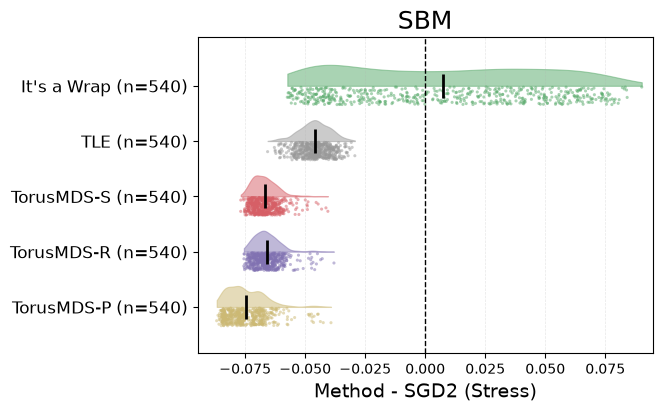

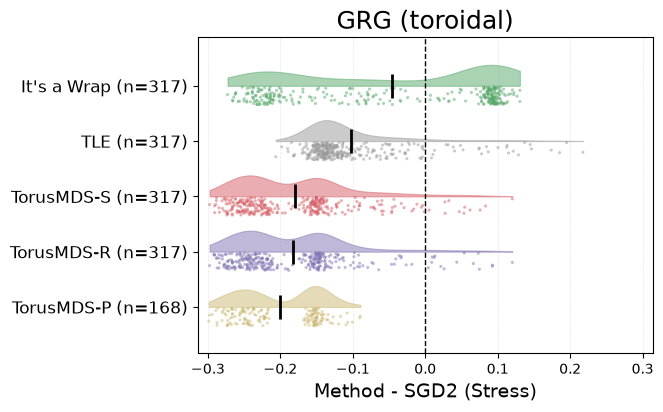

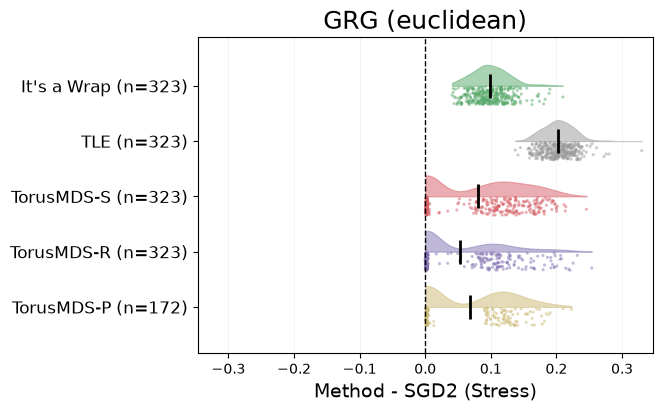

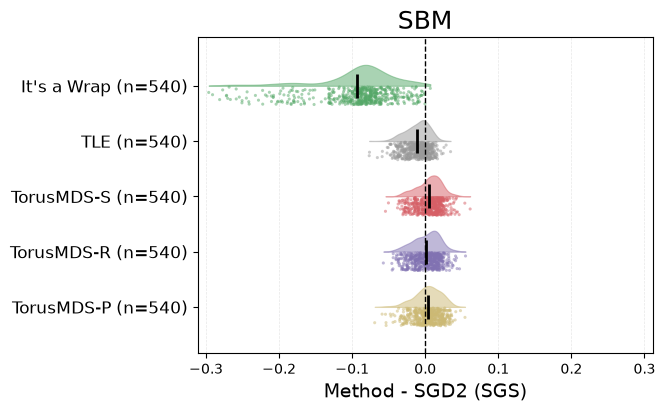

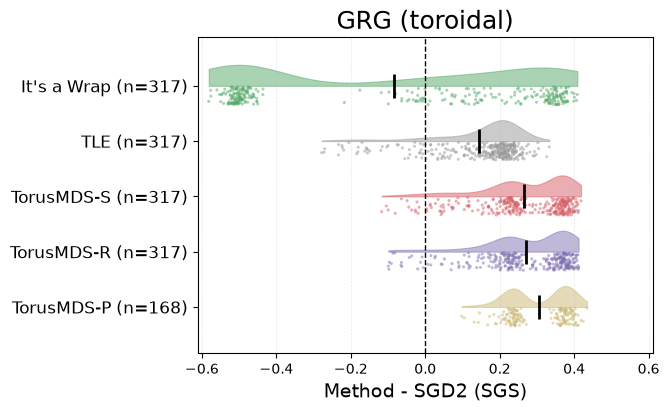

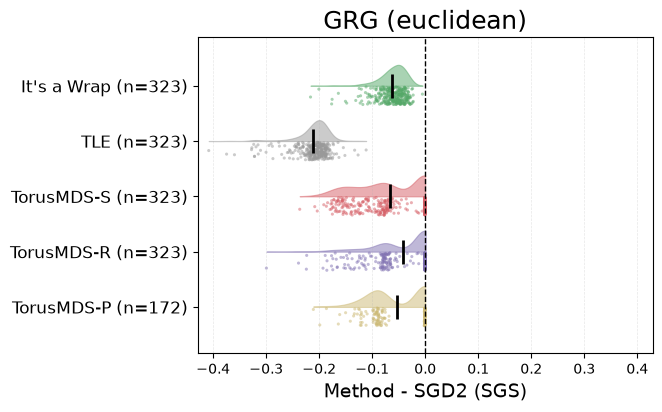

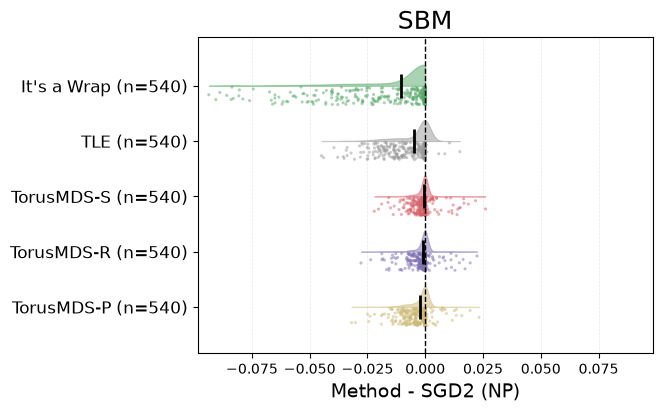

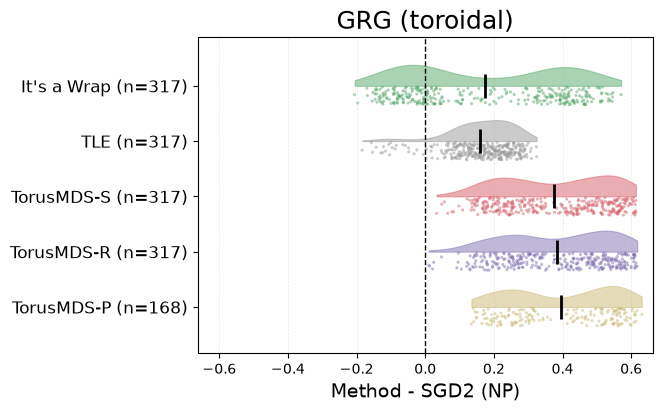

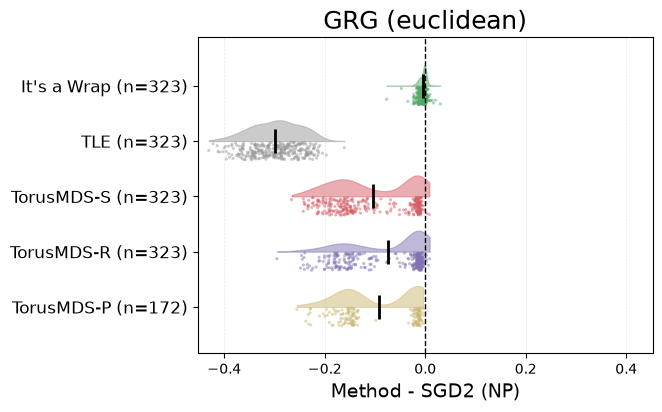

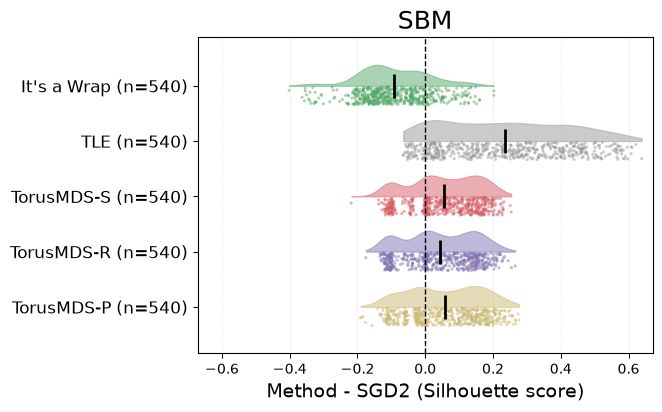

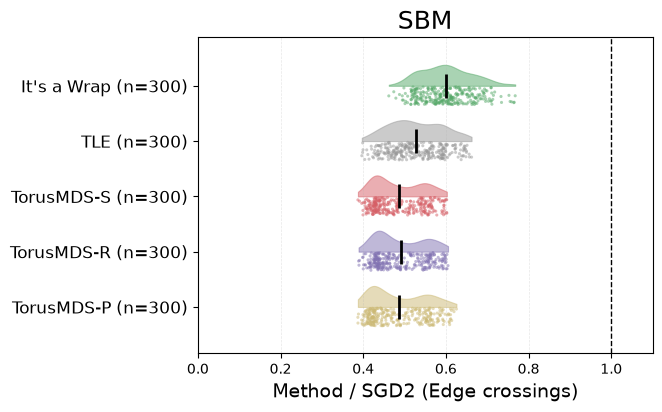

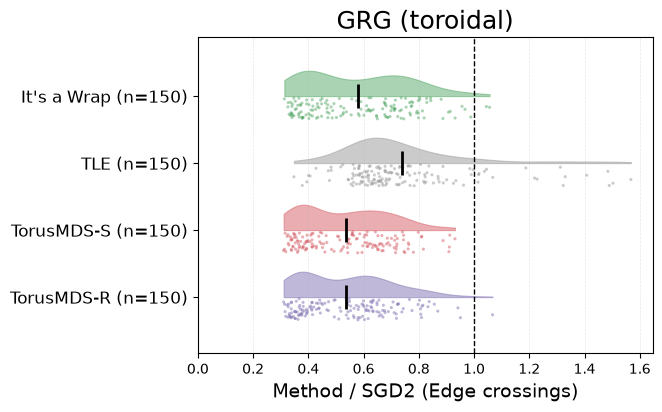

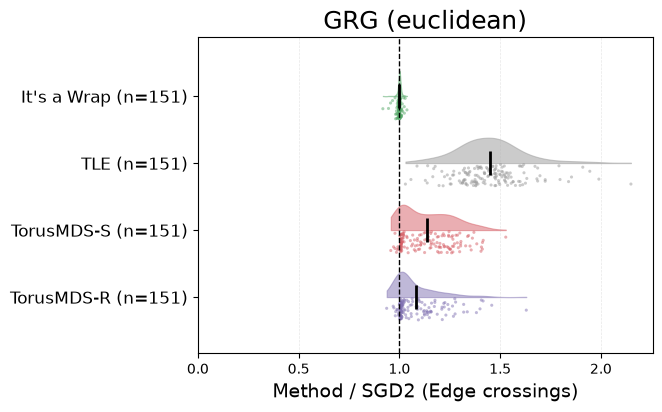

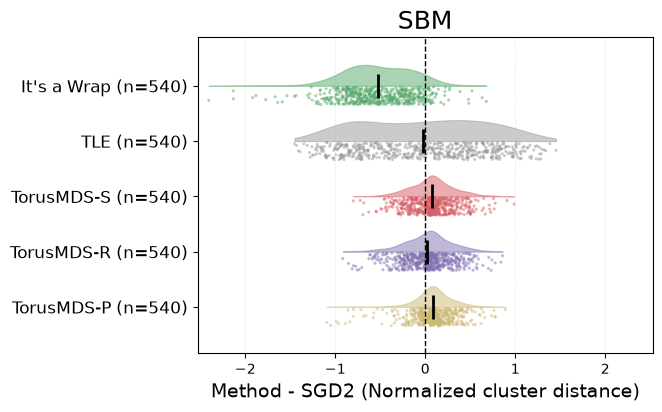

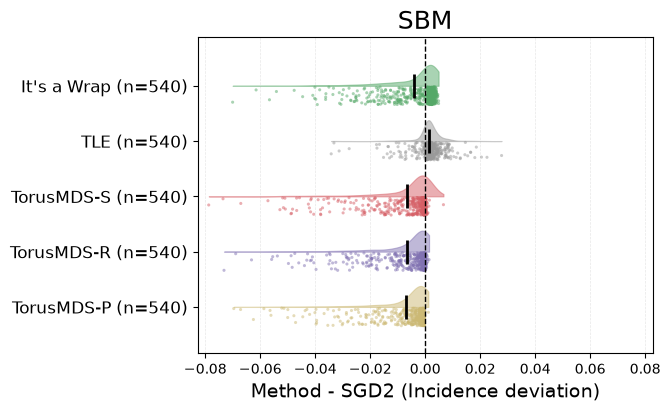

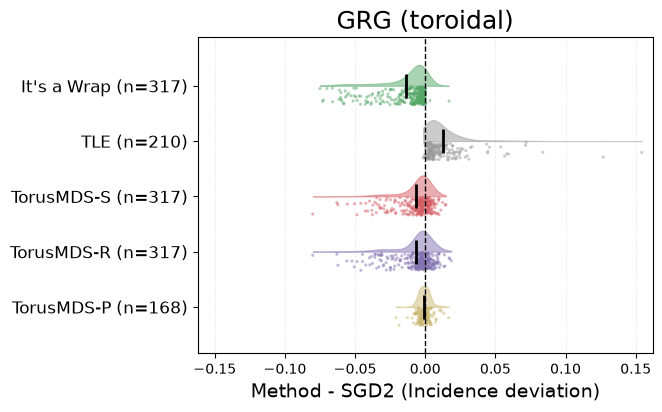

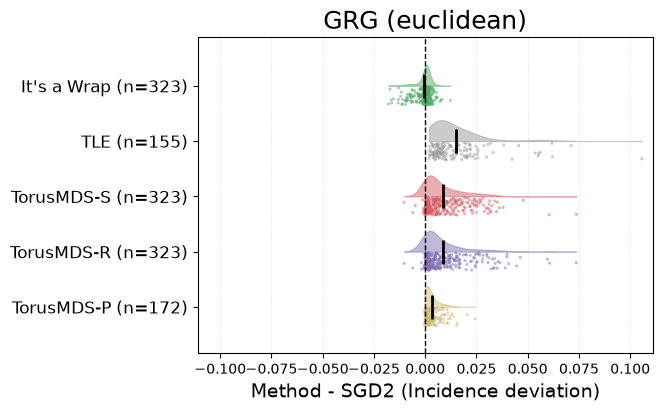

In [11]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import gaussian_kde

# Choose "comparison" (existing result CSVs) or "layout_metrics".
RAINCLOUD_SOURCE = "layout_metrics"
# Restrict tiers if desired, e.g. ("100_1000", "1000_3000").
RAINCLOUD_TIERS = None
RAINCLOUD_MIN_MATCHED = 5
# "spc" or "difference" (uses ratios for crossings).
RAINCLOUD_COMPARISON = "difference"
if RAINCLOUD_COMPARISON not in {"spc", "difference"}:
    raise ValueError("RAINCLOUD_COMPARISON must be spc or difference")
# Shared sets are computed separately for each group and metric.
RAINCLOUD_SHARED_INSTANCES = False # TODO
# None uses methods present in each group; set a list to require specific methods.
RAINCLOUD_METHODS = None
# Relative to PROJECT_ROOT; these are the normalized benchmark comparisons.
RAINCLOUD_COMPARISON_DIR = "verification_experiments/results"

_project_candidates = [Path.cwd(), *Path.cwd().parents]
PROJECT_ROOT = next(p for p in _project_candidates
                    if (p / "verification_experiments/layouts").is_dir()
                    and (p / "results").is_dir())
COMPARISON_DIR = PROJECT_ROOT / RAINCLOUD_COMPARISON_DIR
RAINCLOUD_OUTPUT = COMPARISON_DIR / ("raincloud_" + RAINCLOUD_SOURCE)
RAINCLOUD_OUTPUT.mkdir(parents=True, exist_ok=True)

RAINCLOUD_LABELS = {
    "wrap_python": "It's a Wrap",
    "TorusMDS_spectral_init": "TLE",
    "TorusMDS_smart_1x_scale2": "TorusMDS-S",
    "TorusMDS_random_1x_scale2": "TorusMDS-R",
    "TorusMDS_parallelogram": "TorusMDS-P",
}
RAINCLOUD_COLORS = dict(zip(RAINCLOUD_LABELS,
                           ["#55A868", "#999999", "#D65F66", "#8172B2", "#CCB974"]))
RAINCLOUD_METRICS = {"stress": "Stress", "sgs": "SGS", "np_score": "NP"}
if RAINCLOUD_SOURCE == "layout_metrics":
    RAINCLOUD_METRICS.update({
        "silhouette_score": "Silhouette score",
        "edge_crossings": "Edge crossings",
        "cluster_distance_normalized": "Normalized cluster distance",
        "incidence_angle": "Incidence deviation",
    })
elif RAINCLOUD_SOURCE != "comparison":
    raise ValueError("RAINCLOUD_SOURCE must be 'comparison' or 'layout_metrics'")

def load_raincloud_data(source, tiers=None):
    """Merge shards in memory; never pair graph indices across tiers/shards."""
    frames = []
    for benchmark in ("sbm", "grg", "suitesparse"):
        if source == "comparison":
            paths = [COMPARISON_DIR / f"{benchmark}_normalized_comparison.csv"]
        else:
            paths = sorted((PROJECT_ROOT / "verification_experiments/layouts"
                            / f"{benchmark}_normalized").rglob("layout_metrics.csv"))
            if tiers is not None:
                paths = [p for p in paths if p.parent.parent.name in tiers]
        for path in paths:
            if not path.exists():
                continue
            print("Reading:", path)
            d = pd.read_csv(path)
            if source == "layout_metrics":
                if "metric_status" in d:
                    d = d[d.metric_status.isin(["ok", "partial"])].copy()
                # Derive identity from the actual input location (not exp_idx alone).
                shard = path.parent.relative_to(PROJECT_ROOT).as_posix()
                d["instance"] = shard + ":" + d.exp_idx.astype(str)
            else:
                # Comparison CSVs already use family-wide experiment indices.
                # Their source_shard may identify a method-specific CSV, not a graph.
                d["instance"] = benchmark + ":" + d.exp_idx.astype(str)
            d["benchmark"] = benchmark
            if benchmark == "grg":
                d["group"] = "grg_" + d.graph_type.astype(str)
            else:
                d["group"] = benchmark
            frames.append(d)
    if not frames:
        raise FileNotFoundError(f"No CSVs found for {source}, tiers={tiers}")
    merged = pd.concat(frames, ignore_index=True)
    if "s_gd2" not in set(merged.method):
        raise ValueError("Selected CSVs contain no s_gd2 baseline; check RAINCLOUD_COMPARISON_DIR")
    keys = ["benchmark", "instance", "method"]
    if merged.duplicated(keys).any():
        raise ValueError("Duplicate graph/method identities in raincloud inputs")
    return merged

def raincloud_spc(data, metrics, shared=False):
    """Pair each method with SGD2 separately for each metric's valid rows."""
    frames = []
    for group, d in data.groupby("group"):
        requested = list(RAINCLOUD_LABELS) if RAINCLOUD_METHODS is None else RAINCLOUD_METHODS
        methods = [m for m in requested if m in set(d.method)]
        if RAINCLOUD_METHODS is not None and set(requested) - set(methods):
            warnings.warn(f"{group}: required methods missing; shared plots will be empty")
        shared_ids = {}
        if shared:
            required = ["s_gd2", *(requested if RAINCLOUD_METHODS is not None else methods)]
            for metric in metrics:
                if metric not in d:
                    continue
                wide = d.pivot(index="instance", columns="method", values=metric).reindex(columns=required)
                finite = np.isfinite(wide.apply(pd.to_numeric, errors="coerce"))
                shared_ids[metric] = wide.index[finite.all(axis=1)]
        base = d[d.method == "s_gd2"].set_index("instance")
        for method in methods:
            other = d[d.method == method].set_index("instance")
            common = base.index.intersection(other.index)
            for metric in metrics:
                if metric not in d or common.empty:
                    continue
                matched = common.intersection(shared_ids[metric]) if shared else common
                a = pd.to_numeric(other.loc[matched, metric], errors="coerce").to_numpy()
                b = pd.to_numeric(base.loc[matched, metric], errors="coerce").to_numpy()
                valid = np.isfinite(a) & np.isfinite(b)
                a, b = a[valid], b[valid]
                denom = np.maximum(np.abs(a), np.abs(b))
                # Both zero => no change. Signed scores can produce SPC up to 200%.
                spc = np.divide(100 * (a - b), denom,
                                out=np.zeros_like(a), where=denom != 0)
                ratio = np.divide(a, b, out=np.full_like(a, np.nan), where=b != 0)
                frames.append(pd.DataFrame({"group": group, "method": method,
                                            "metric": metric, "spc": spc,
                                            "difference": a - b, "ratio": ratio, "instance": matched[valid]}))
    return pd.concat(frames, ignore_index=True) if frames else pd.DataFrame(
        columns=["group", "method", "metric", "spc", "difference", "ratio", "instance"])

def half_violin_strip(ax, sub, present_methods, seed=0, value_col="spc"):
    rng = np.random.default_rng(seed)
    for yi, method in enumerate(present_methods):
        vals = sub.loc[sub.method == method, value_col].to_numpy()
        color = RAINCLOUD_COLORS[method]
        if len(vals) >= 2 and np.ptp(vals) > 0:
            xs = np.linspace(vals.min(), vals.max(), 200)
            try:
                density = gaussian_kde(vals)(xs)
                ax.fill_between(xs, yi, yi - .38 * density / density.max(),
                                color=color, alpha=.5, linewidth=.8, edgecolor=color)
            except np.linalg.LinAlgError:
                pass  # Effectively constant samples still get points and a mean.
        ax.scatter(vals, yi + rng.uniform(.02, .34, len(vals)),
                   s=5, alpha=.5, color=color, edgecolors="none")
        ax.scatter(np.mean(vals), yi, marker="|", s=300,
                   linewidths=2, color="black", zorder=5)

raincloud_data = load_raincloud_data(RAINCLOUD_SOURCE, RAINCLOUD_TIERS)
raincloud_spc_all = raincloud_spc(raincloud_data, RAINCLOUD_METRICS, shared=RAINCLOUD_SHARED_INSTANCES)
print("Selected source:", RAINCLOUD_SOURCE, "| shared instances:", RAINCLOUD_SHARED_INSTANCES)
RAINCLOUD_OUTPUT = RAINCLOUD_OUTPUT / ("shared" if RAINCLOUD_SHARED_INSTANCES else "pairwise") / RAINCLOUD_COMPARISON
RAINCLOUD_OUTPUT.mkdir(parents=True, exist_ok=True)
print(raincloud_data.groupby(["group", "method"]).size().unstack(fill_value=0))
for method in RAINCLOUD_LABELS:
    if method not in set(raincloud_data.method):
        warnings.warn(f"No {method} rows in the selected source")
if RAINCLOUD_SOURCE == "layout_metrics":
    print("Crossings use only evaluated graphs; cluster metrics require labels.")
    print("Incidence excludes undefined layouts. Counts can differ by metric/method.")

raincloud_group_labels = {"sbm": "SBM", "grg_toroidal": "GRG (toroidal)",
                         "grg_euclidean": "GRG (euclidean)", "suitesparse": "SuiteSparse"}
fig_width_in = 424 / 72.27
for metric, label in RAINCLOUD_METRICS.items():
    value_col = ("spc" if RAINCLOUD_COMPARISON == "spc" else
                 "ratio" if metric == "edge_crossings" else "difference")
    reference = 1 if value_col == "ratio" else 0
    for group, title in raincloud_group_labels.items():
        sub = raincloud_spc_all[(raincloud_spc_all.group == group)
                               & (raincloud_spc_all.metric == metric)]
        if value_col == "ratio":
            excluded = sub["ratio"].isna().sum()
            if excluded:
                print(f"{group} crossings: excluded {excluded} method/graph pairs with zero baseline")
        sub = sub[np.isfinite(sub[value_col])]
        present = [m for m in RAINCLOUD_LABELS
                   if (sub.method == m).sum() >= RAINCLOUD_MIN_MATCHED]
        if not present:
            continue  # No empty cluster panels for graphs without cluster labels.
        fig, ax = plt.subplots(figsize=(fig_width_in, fig_width_in * .7))
        half_violin_strip(ax, sub, present, value_col=value_col)
        ax.axvline(reference, color="black", linestyle="--", linewidth=1)
        values = sub.loc[sub.method.isin(present), value_col]
        if value_col == "ratio":
            ax.set_xlim(0, max(1.1, 1.05 * values.max()))
        else:
            limit = max(105 if value_col == "spc" else .01, 1.05 * values.abs().max())
            ax.set_xlim(-limit, limit)
        ax.set_yticks(range(len(present)))
        ax.set_yticklabels([f"{RAINCLOUD_LABELS[m]} (n={(sub.method == m).sum()})"
                            for m in present], fontsize=12)
        ax.set_ylim(len(present) - .16, -.88)
        comparison_label = {"spc": "SPC vs SGD2 (%)", "difference": "Method - SGD2",
                            "ratio": "Method / SGD2"}[value_col]
        ax.set_xlabel(f"{comparison_label} ({label})", fontsize=14)
        ax.set_title(title, fontsize=18)
        ax.grid(axis="x", linestyle="--", alpha=.3)
        fig.savefig(RAINCLOUD_OUTPUT / f"combined_{value_col}_raincloud_{metric}_{group}.png",
                    dpi=150, bbox_inches="tight")
        plt.show()



## Win rate vs `s_gd2`

The median/CI numbers above can be dominated by a handful of large SPC values
even though SPC is bounded (a method can have a middling median while still
beating `s_gd2` on most individual graphs, or vice versa). This shows the
fraction of matched instances where a method is strictly better than
`s_gd2` -- lower stress, or higher SGS/NP -- independent of by how much.

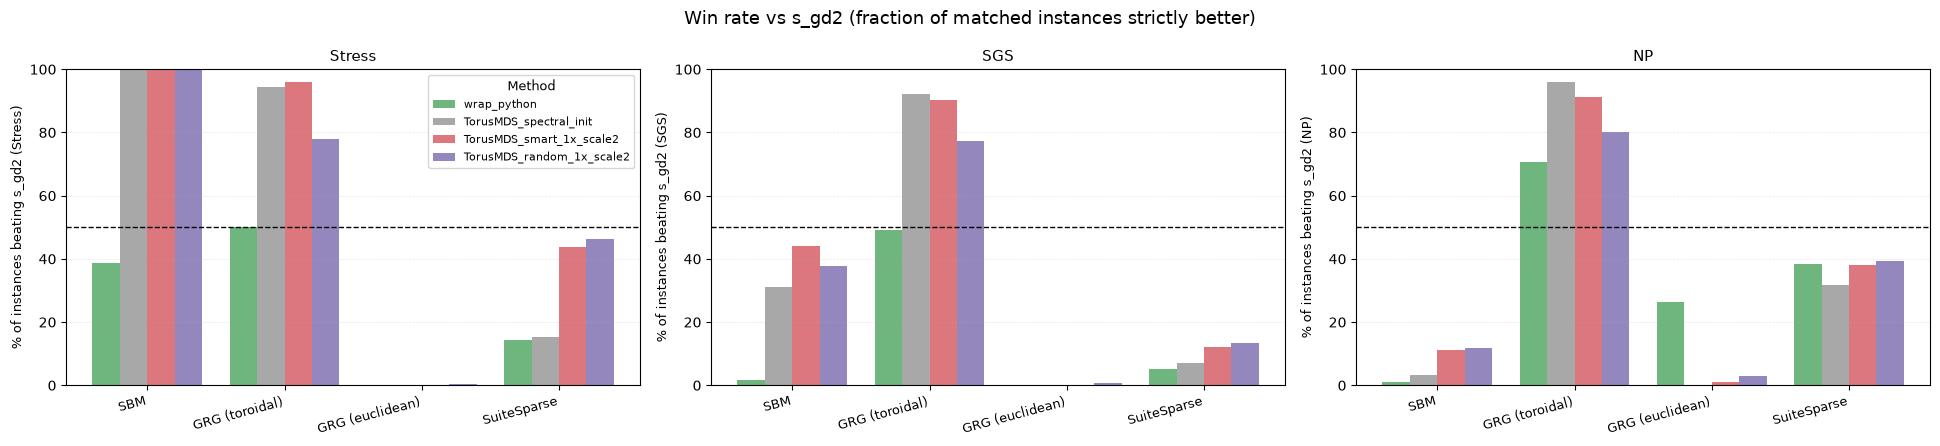

In [12]:
def win_rate(vals, higher_is_better):
    vals = np.asarray(vals, dtype=float)
    vals = vals[~np.isnan(vals)]
    if len(vals) < MIN_N_FOR_DIST:
        return np.nan
    beats = vals > 0 if higher_is_better else vals < 0
    return 100 * np.mean(beats)


fig, axes = plt.subplots(1, len(ALL_METRICS), figsize=(6.5 * len(ALL_METRICS), 4.5), squeeze=False)
width = 0.8 / len(METHODS_NO_BASE)
x = np.arange(len(GROUPS))

for mi, metric in enumerate(ALL_METRICS):
    ax = axes[0][mi]
    higher_is_better = METRIC_HIGHER_IS_BETTER[metric]
    for mj, m in enumerate(METHODS_NO_BASE):
        rates = [win_rate(spc_all[(spc_all['group'] == g) & (spc_all['metric'] == metric) & (spc_all['method'] == m)]['spc'].values,
                           higher_is_better)
                 for g in GROUPS]
        offsets = x + (mj - (len(METHODS_NO_BASE) - 1) / 2) * width
        ax.bar(offsets, rates, width=width, color=COLORS[m], alpha=0.85, label=m)

    ax.axhline(50, color='black', linestyle='--', linewidth=1)
    ax.set_xticks(x)
    ax.set_xticklabels([GROUP_LABELS[g] for g in GROUPS], rotation=15, ha='right', fontsize=9)
    ax.set_ylabel(f'% of instances beating s_gd2 ({METRIC_LABELS[metric]})', fontsize=9)
    ax.set_ylim(0, 100)
    ax.set_title(METRIC_LABELS[metric], fontsize=11)
    ax.grid(axis='y', linestyle='--', alpha=0.3)

axes[0][0].legend(title='Method', fontsize=8, title_fontsize=9)
fig.suptitle('Win rate vs s_gd2 (fraction of matched instances strictly better)', fontsize=13)
fig.tight_layout()
plt.savefig(f'{RESULTS_PATH}/combined_winrate.png', dpi=150, bbox_inches='tight')
plt.show()

## Drawing individual instances

Assumes the `layouts/` tree (graph + coords files, as written by
`run_embeddings`) is present locally alongside `results/` -- adjust
`LAYOUTS_ROOT` below if it's mounted somewhere else.

One wrinkle: `exp_idx` in `dfs[benchmark]` / `spc_all` (used everywhere
above) is **not** the same `exp_idx` the actual `.npy`/`.npz` files on disk
are keyed by. `merge_results.py` renumbers `exp_idx` to be unique across the
whole merged CSV when it concatenates per-shard result files, and doesn't
persist the original -- only `source_shard` (which per-shard CSV a row came
from) survives. `draw_instance()` below undoes that renumbering
deterministically (`merge_results.py`'s scheme is order-preserving: the
per-shard exp_idx values are sorted and reassigned consecutively), so you
can pass it the exp_idx exactly as it appears in the tables/plots above.

In [13]:
import os
import re
import sys
from types import SimpleNamespace

sys.path.insert(0, os.path.abspath('..'))
from modules.experiment_runner import coords_path, graph_path, load_graph
from modules.visualization import plot_embedding, plot_embedding_with_torus_edges

LAYOUTS_ROOT = '../layouts'
NON_PERIODIC_METHODS = {'s_gd2'}   # s_gd2's output isn't confined to [0,1)^2 -- see draw_layouts.py


def resolve_shard_dir(source_shard, benchmark, layouts_root=LAYOUTS_ROOT):
    """Map a merged CSV's `source_shard` (a results/*_comparison.csv path) back to the
    layouts/ directory it was computed from, using run_embed_array.sbatch's own
    output-dir convention (see run_metrics_array.sbatch's SHARD_NAME construction)."""
    stem = re.sub(r'_comparison\.csv$', '', os.path.basename(source_shard))
    if benchmark in ('sbm', 'grg'):
        m = re.match(rf'{benchmark}_normalized_(\d+)_(\d+)_shard_(\d+)$', stem)
        if not m:
            raise ValueError(f"Can't parse source_shard {source_shard!r} for benchmark {benchmark!r}")
        n_min, n_max, shard_i = m.groups()
        return os.path.join(layouts_root, f'{benchmark}_normalized', f'{n_min}_{n_max}', f'shard_{shard_i}')
    elif benchmark == 'suitesparse':
        m = re.match(r'suitesparse_normalized_shard_(\d+)$', stem)
        if not m:
            raise ValueError(f"Can't parse source_shard {source_shard!r} for benchmark {benchmark!r}")
        return os.path.join(layouts_root, 'suitesparse_normalized', f'shard_{m.group(1)}')
    raise ValueError(f'Unknown benchmark {benchmark!r}')


def _shard_csv_path(source_shard):
    # source_shard is stored as a repo-root-relative path (e.g.
    # "results/sbm_..._comparison.csv"), written by merge_results.py when run
    # from the repo root -- this notebook's cwd is verification_experiments/,
    # so resolve it the same way dfs[...] itself is loaded above (via '../').
    return source_shard if os.path.isabs(source_shard) else os.path.join('..', source_shard)


def recover_raw_exp_idx(merged_df, source_shard, merged_exp_idx):
    """Undo merge_results.py's exp_idx renumbering: it maps each shard CSV's sorted
    unique exp_idx values to a consecutive block starting at that shard's first new
    id, in order. Re-deriving that block's start (the min exp_idx this merged_df has
    for this source_shard) recovers the original per-shard exp_idx exactly."""
    shard_df = pd.read_csv(_shard_csv_path(source_shard))
    old_ids = sorted(shard_df['exp_idx'].unique())
    next_exp_idx = merged_df.loc[merged_df['source_shard'] == source_shard, 'exp_idx'].min()
    return old_ids[int(merged_exp_idx - next_exp_idx)]


def draw_instance(exp_idx, benchmark, method, ax=None, layouts_root=LAYOUTS_ROOT,tsnet=True,output=None):
    """Draw one persisted (graph, method) layout, looked up the same way exp_idx/
    benchmark/method appear in dfs[benchmark] and spc_all above. `benchmark` is sbm/
    grg/suitesparse (not a `group` like grg_toroidal -- use GROUP_BENCHMARK[group]
    if starting from a `group` value). Returns (G, X) for further inspection.

    Note: dfs[benchmark] (compute_metrics.py's output) only ever contains rows it
    successfully scored -- there's no 'status' column to check here (that only
    exists in the raw embedding runs.csv manifest), so a matching row already
    implies coords existED when results/ was computed. If your local layouts/
    tree is a different/older snapshot than whatever produced results/ (e.g.
    partially synced), the coords file can still be missing locally -- that
    raises FileNotFoundError with a clear message below rather than the raw
    numpy traceback."""
    merged_df = dfs[benchmark]
    matches = merged_df[(merged_df['exp_idx'] == exp_idx) & (merged_df['method'] == method)]
    if len(matches) == 0:
        raise ValueError(f'No row for benchmark={benchmark!r} exp_idx={exp_idx} method={method!r}')
    row = matches.iloc[0]

    source_shard = row['source_shard']
    shard_dir = resolve_shard_dir(source_shard, benchmark, layouts_root)
    raw_exp_idx = recover_raw_exp_idx(merged_df, source_shard, exp_idx)

    cpath = coords_path(shard_dir, raw_exp_idx, method)
    if not os.path.exists(cpath):
        raise FileNotFoundError(
            f"{cpath} not found locally, even though {benchmark}'s results CSV has a row for "
            f"exp_idx={exp_idx} method={method!r}. Your local {layouts_root!r} tree is likely a "
            f"different/older snapshot than whatever layouts/ produced results/{benchmark}_"
            f"normalized_comparison.csv (results/ is small and easy to pull; layouts/ coords are "
            f"much bigger and easy to leave out of sync)."
        )
    G = load_graph(graph_path(shard_dir, raw_exp_idx))
    X = np.load(cpath)

    own_ax = ax is None
    if own_ax:
        _, ax = plt.subplots(figsize=(5.5, 5.5))

    if method in NON_PERIODIC_METHODS:
        lo, hi = X.min(axis=0), X.max(axis=0)
        span = np.where(hi > lo, hi - lo, 1.0)
        plot_embedding((X - lo) / span, G, ax=ax,tsnet_style=tsnet)
    else:
        alpha, r0, r1 = row.get('alpha_fit'), row.get('r0_fit'), row.get('r1_fit')
        torus = SimpleNamespace(
            torus_embedding_=None,
            alpha_=float(alpha) if pd.notna(alpha) else 1.0,
            r0_=float(r0) if pd.notna(r0) else 1.0,
            r1_=float(r1) if pd.notna(r1) else 1.0,
            theta_=np.pi / 2,
        )
        plot_embedding_with_torus_edges(X=X, G=G, torus=torus, ax=ax, tsnet_style=tsnet)

    stress_str = f", stress={row['stress']:.3f}" if pd.notna(row.get('stress')) else ""
    ax.set_title(f'{BENCH_LABELS.get(benchmark, benchmark)} exp_idx={exp_idx} n={G.number_of_nodes()}\n{method}{stress_str}', fontsize=8)

    if own_ax:
        plt.tight_layout()
        if output: 
            plt.savefig(output,dpi=150)
        else: 
            plt.show()
    return G, X


def compare_instance(exp_idx, benchmark, method, baseline='s_gd2'):
    """Side-by-side: `method`'s layout next to `baseline`'s, for the same graph."""
    fig, axes = plt.subplots(1, 2, figsize=(11, 5.5))
    draw_instance(exp_idx, benchmark, baseline, ax=axes[0],tsnet=True)
    draw_instance(exp_idx, benchmark, method, ax=axes[1],tsnet=True)
    fig.tight_layout()
    plt.show()

### Example: TorusMDS/spectral instances that beat `s_gd2` most, on SuiteSparse

Pulls the most-negative (best) stress SPC instances for a method vs `s_gd2`
straight out of `spc_all` (already computed above), then draws each one next
to its `s_gd2` layout for comparison.

In [14]:
def best_instances(group, method, metric='stress', n=3, ascending=True):
    """The n most-extreme matched instances (lowest SPC if ascending, i.e. best for
    stress/runtime) for `method` vs s_gd2 within a `group` (e.g. 'suitesparse',
    'grg_toroidal') -- reads straight from spc_all, computed earlier in this notebook."""
    sub = spc_all[(spc_all['group'] == group) & (spc_all['metric'] == metric) & (spc_all['method'] == method)]
    return sub.sort_values('spc', ascending=ascending)[['exp_idx', 'spc']].head(n)


group = 'suitesparse'
for method in ['TorusMDS_spectral_init', 'TorusMDS_smart_1x_scale2', 'TorusMDS_random_1x_scale2']:
    best = best_instances(group, method, metric='stress', n=20, ascending=True)
    print(f'\n=== {method}: best stress SPC vs s_gd2 on SuiteSparse ===')
    print(best)
    for _, r in best.iterrows():
        try:
            compare_instance(int(r['exp_idx']), group, method)
        except FileNotFoundError as e:
            plt.close('all')   # drop the partially-drawn figure (baseline panel only) left open
            print(f'  skipping exp_idx={int(r["exp_idx"])}: {e}')


=== TorusMDS_spectral_init: best stress SPC vs s_gd2 on SuiteSparse ===
       exp_idx        spc
22420      115 -82.177356
23254      949 -81.747078
23338     1033 -76.330898
23001      696 -74.823804
23286      981 -74.488210
23259      954 -74.377981
23000      695 -73.940564
23053      748 -73.512741
23102      797 -72.850270
22949      644 -72.408397
22844      539 -70.245885
23234      929 -65.737862
23004      699 -64.318528
23257      952 -63.157429
22998      693 -61.604318
22532      227 -61.493655
23182      877 -59.209831
23050      745 -56.432600
23207      902 -51.045771
23156      851 -50.655036
  skipping exp_idx=115: [Errno 2] No such file or directory: '../results/suitesparse_normalized_shard_11_comparison.csv'
  skipping exp_idx=949: [Errno 2] No such file or directory: '../results/suitesparse_normalized_shard_8_comparison.csv'
  skipping exp_idx=1033: [Errno 2] No such file or directory: '../results/suitesparse_normalized_shard_9_comparison.csv'
  skipping exp_idx=

FileNotFoundError: [Errno 2] No such file or directory: '../results/suitesparse_normalized_shard_4_comparison.csv'

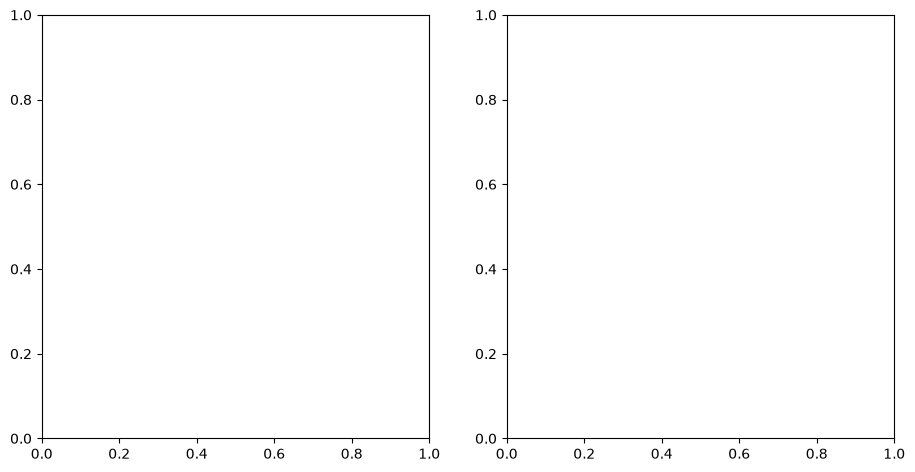

In [15]:
compare_instance(768, "suitesparse", "TorusMDS_smart_1x_scale2")

In [ ]:
num = 454-21
group = "suitesparse"

draw_instance(num,group,"TorusMDS_spectral_init",output=f"../figures/{num}_{group}_spectral.pdf")
draw_instance(num,group, "TorusMDS_smart_1x_scale2",output=f"../figures/{num}_{group}_TorusMDS_smart_1x_scale2.pdf")
draw_instance(num,group, "TorusMDS_random_1x_scale2",output=f"../figures/{num}_{group}_TorusMDS_random_1x_scale2.pdf")
draw_instance(num,group, "s_gd2",output=f"../figures/{num}_{group}_s_gd2.pdf")
draw_instance(num,group, "wrap_python",output=f"../figures/{num}_{group}_wrap_python.pdf")